### Project-3 EV-Financial Data Analysis

## About the Project

The **EV Financial Data Analysis** project focuses on analyzing electric vehicle (EV) loan applications to understand business performance, financial affordability, and credit risk. The main objective is to identify key factors influencing loan approval decisions, evaluate customers' repayment capacity, and assess financial risks associated with EV financing.

Using Python, Pandas, NumPy, and data visualization techniques, this project explores loan application data and generates meaningful insights to support better financial decision-making.

## Project Objectives

### 1. Business Performance Analysis
- Analyze total loan application volumes and approval rates.
- Calculate average loan amounts and approval percentages.
- Evaluate city-wise loan application performance.
- Identify cities with higher approval and rejection rates.

### 2. Financial Analysis
- Calculate EMI affordability based on customers' income.
- Analyze disposable income after monthly expenses and EMI payments.
- Evaluate down-payment ratios to understand customers' initial financial contribution.
- Measure overall loan exposure and financial commitments.

### 3. Credit Risk Analysis
- Compare loan rejection rates across different credit score categories.
- Analyze credit risk based on employment types.
- Evaluate the impact of previous loan defaults on approval decisions.
- Identify customer segments with higher credit risk.

## Tools & Technologies
- **Python** – Data analysis and calculations.
- **Pandas & NumPy** – Data cleaning, manipulation, and analysis.
- **Matplotlib & Seaborn** – Data visualization.
- **Jupyter Notebook** – Exploratory Data Analysis (EDA).

## Expected Outcomes

- Understand EV loan business performance across different cities.
- Identify factors affecting loan approval and rejection decisions.
- Evaluate customer financial affordability.
- Identify high-risk customer segments.
- Generate data-driven insights to improve lending decisions and credit risk management.

### 🐍✨Phase -1

### 💻 Import Libraries 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor

### 📊Load and Explore Excel Data file 

In [5]:
ev_financial=pd.read_excel('ev_financing_analyst_dataset.xlsx')

### Fetching 5 records from the top of the DataFrame

In [6]:
ev_financial.head()

,Application_ID,City,Employment_Type,Vehicle_Price_INR,Down_Payment_INR,Loan_Amount_INR,Interest_Rate_Annual_Pct,Tenure_Months,Monthly_EMI_INR,Monthly_Income_INR,Monthly_Expenses_INR,Debt_to_Income_Ratio,Credit_Score,Prior_Loan_Default_Flag,Application_Decision,Application_Year,Down_Payment_Pct,Monthly_Disposable_Income_INR,EMI_to_Income_Pct
0,EVF001,Delhi,Private,1250000,200000,1050000,9.5,48,26330,95000,72000,0.82,720,0,Approved,2026,16.0,23000,27.7
1,EVF002,Mumbai,Private,1800000,300000,1500000,9.2,60,31350,110000,84000,0.76,755,0,Approved,2026,16.7,26000,28.5
2,EVF003,Bengaluru,Gig Worker,950000,100000,850000,11.5,48,22050,65000,52000,0.68,690,1,Approved with Conditions,2026,10.5,13000,33.9
3,EVF004,Pune,Private,1450000,250000,1200000,9.8,60,25450,88000,68000,0.79,735,0,Approved,2026,17.2,20000,28.9
4,EVF005,Hyderabad,Self-employed,2200000,400000,1800000,10.5,60,38650,150000,105000,0.72,710,0,Approved,2026,18.2,45000,25.8


In [ ]:
### Fetching bottom five records from the table 

In [7]:
ev_financial.tail()

,Application_ID,City,Employment_Type,Vehicle_Price_INR,Down_Payment_INR,Loan_Amount_INR,Interest_Rate_Annual_Pct,Tenure_Months,Monthly_EMI_INR,Monthly_Income_INR,Monthly_Expenses_INR,Debt_to_Income_Ratio,Credit_Score,Prior_Loan_Default_Flag,Application_Decision,Application_Year,Down_Payment_Pct,Monthly_Disposable_Income_INR,EMI_to_Income_Pct
25,EVF026,Chennai,Private,1500000,250000,1250000,9.6,60,26500,90000,70000,0.82,755,0,Approved,2026,16.7,20000,29.4
26,EVF027,Delhi,Gig Worker,1050000,100000,950000,12.4,48,25200,62000,41000,0.65,660,1,Rejected,2026,9.5,21000,40.6
27,EVF028,Jaipur,Self-employed,1600000,250000,1350000,10.9,60,29300,85000,59000,0.71,700,0,Approved,2026,15.6,26000,34.5
28,EVF029,Kolkata,Private,1250000,200000,1050000,9.8,48,26400,80000,62000,0.79,735,0,Approved,2026,16.0,18000,33.0
29,EVF030,Ahmedabad,Gig Worker,900000,100000,800000,12.6,36,26500,60000,39000,0.62,650,1,Rejected,2026,11.1,21000,44.2


### Checking Data types of all columns

In [8]:
ev_financial.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Application_ID                 30 non-null     object 
 1   City                           30 non-null     object 
 2   Employment_Type                30 non-null     object 
 3   Vehicle_Price_INR              30 non-null     int64  
 4   Down_Payment_INR               30 non-null     int64  
 5   Loan_Amount_INR                30 non-null     int64  
 6   Interest_Rate_Annual_Pct       30 non-null     float64
 7   Tenure_Months                  30 non-null     int64  
 8   Monthly_EMI_INR                30 non-null     int64  
 9   Monthly_Income_INR             30 non-null     int64  
 10  Monthly_Expenses_INR           30 non-null     int64  
 11  Debt_to_Income_Ratio           30 non-null     float64
 12  Credit_Score                   30 non-null     int64

## 🧹 Phase 2: Data Cleaning Process

1. 🔍 **Check Duplicate Records** – Identify duplicate records in the DataFrame.
2. 🩹 **Handle Missing Values** – Identify and manage missing or null values.
3. 📊 **Detect and Remove Outliers** – Identify and handle outliers in the dataset.
4. 🗑️ **Remove Irrelevant Data** – Eliminate unnecessary or irrelevant information.
5. 🔠 **Standardize Capitalization** – Maintain consistent capitalization across text values.
6. 🔄 **Convert Data Types** – Convert columns to the appropriate data types. 
7. 🧾 **Clean Formatting** – Ensure consistent formatting throughout the dataset.
8. 🌐 **Language Translation** – Translate text into the required language where necessary.
9. 🛠️ **Fix Errors** – Correct spelling mistakes, inconsistent values, and data entry errors.

In [14]:
# 1.🔍 Check Duplicate Records – Identify duplicate records in the DataFrame.
print('No. of duplicate records found in DataFrame:',ev_financial.duplicated().sum())


No. of duplicate records found in DataFrame: 0


In [22]:
# 🩹 Handle Missing Values – Identify and manage missing or null values.
print('Check missing values from every columns:')
ev_financial.isnull().sum()

print("No missing values found")

Check missing values from every columns:
No missing values found


### Phase-3 Business Performance Analysis
In this analysis we should check main 4 important KPIs for checking the business performance
1. Application Volumes 📋
2. Approval Rates ✅
3. Average Loan Amount 💰
4. City-wise Performance 🏙️


### 💡 Conclusion: After Performed Business Analysis

 After completing analysis  the project report found following important things:
1. Application Volume: Delhi mein sabse zyada 4 loan applications receive hue.
2. Approval Rate: Overall approval rate 90% hai, conditional approvals ko include karne par.
3. Average Loan: Average loan amount ₹11.90 lakh hai.
4. Best City: Hyderabad mein highest average loan amount ₹14.83 lakh hai aur 100% approval rate hai.
5. Improvement Area: Ahmedabad aur Kolkata mein approval rate 66.7% hai. In cities mein loan rejection reasons investigate karne chahiye.

## Calculate Application Volumes 📋
Business Question: How many customers are apply for EV loan?

In [43]:
total_applications = len(ev_financial)

print("Total Applications for EV Loan:", total_applications)

Total Applications for EV Loan: 30


In [27]:
print('City wise Loan application:')
city_applications = ev_financial['City'].value_counts()
print(city_applications)

City wise Loan application:
City
Delhi        4
Mumbai       3
Bengaluru    3
Pune         3
Hyderabad    3
Chennai      3
Jaipur       3
Kolkata      3
Ahmedabad    3
Lucknow      2
Name: count, dtype: int64


## 2. Application Approval \ Rejected Rate calculate 

In [35]:
# Count approved applications
approved = ev_financial[
    ev_financial['Application_Decision'] == 'Approved'
].shape[0]

# Count approved with conditions
approval_with_condition = ev_financial[ev_financial['Application_Decision'] == 'Approved with Conditions'].shape[0]

# Count rejected application
rejected = ev_financial[ev_financial['Application_Decision'] == 'Rejected'].shape[0]


# Total applications
total = len(ev_financial)

# Calculate percentages
approval_rate = (approved / total) * 100

approval_with_condition_rate = (approval_with_condition / total) * 100

rejected = (rejected / total) * 100

# Print results
print("Approval Rate:", round(approval_rate, 2), "%")
print("Approved with Conditions Rate:",
      round(approval_with_condition_rate, 2), "%")

print("Rejected Rate:", round(rejected, 2), "%")

Approval Rate: 70.0 %
Approved with Conditions Rate: 20.0 %
Rejected Rate: 10.0 %


### Average Loan Amount Analysis 💰

In [36]:
average_loan = ev_financial['Loan_Amount_INR'].mean()

print("Average Loan Amount:", average_loan)

Average Loan Amount: 1190000.0


### City-wise Performance Analysis 🏙️

In [38]:
# Float formatting (scientific notation remove)
pd.options.display.float_format = '{:,.2f}'.format

city_performance = ev_financial.groupby('City').agg(

    Total_Applications=('Application_ID', 'count'),

    Approved=('Application_Decision',
        lambda x: x.isin([
            'Approved',
            'Approved with Conditions'
        ]).sum()),

    Rejected=('Application_Decision',
        lambda x: (x == 'Rejected').sum()),

    Average_Loan_Amount=('Loan_Amount_INR', 'mean')

)

city_performance['Approval_Rate'] = (
    city_performance['Approved'] /
    city_performance['Total_Applications']
) * 100

city_performance

,Total_Applications,Approved,Rejected,Average_Loan_Amount,Approval_Rate
City,,,,,
Ahmedabad,3,2,1,"1,250,000.00",66.67
Bengaluru,3,3,0,"1,200,000.00",100.00
Chennai,3,3,0,"1,033,333.33",100.00
Delhi,4,3,1,"1,155,000.00",75.00
Hyderabad,3,3,0,"1,483,333.33",100.00
Jaipur,3,3,0,"1,183,333.33",100.00
Kolkata,3,2,1,"1,050,000.00",66.67
Lucknow,2,2,0,"875,000.00",100.00
Mumbai,3,3,0,"1,466,666.67",100.00


### Business Performance-Data Visualization 📊

### City-wise Application Volume

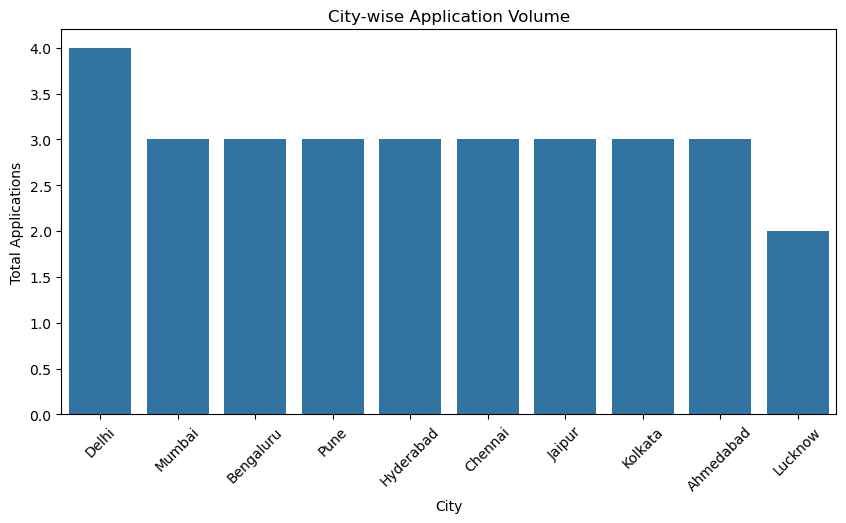

In [40]:
plt.figure(figsize=(10,5))

sns.countplot(data=ev_financial, x='City',order=ev_financial['City'].value_counts().index)

plt.title('City-wise Application Volume')
plt.xlabel('City')
plt.ylabel('Total Applications')
plt.xticks(rotation=45)

plt.show()

### City-wise Approval Rate

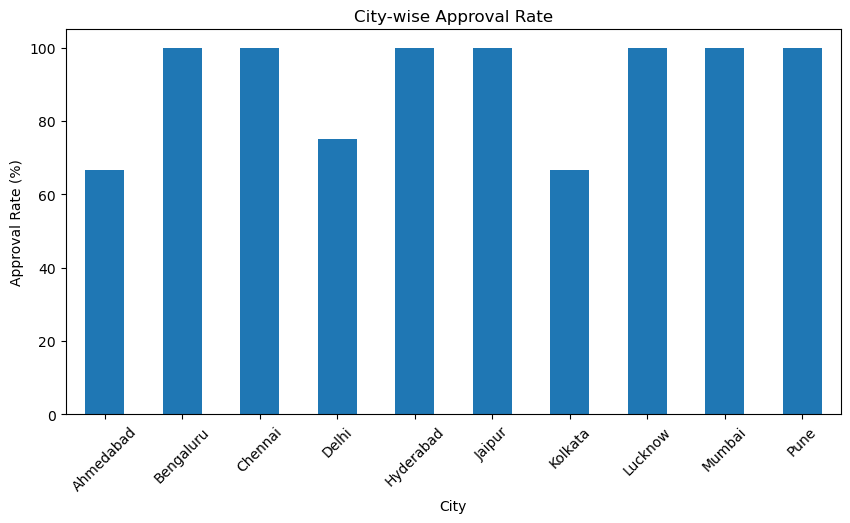

In [41]:
city_performance['Approval_Rate'].plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('City-wise Approval Rate')
plt.xlabel('City')
plt.ylabel('Approval Rate (%)')
plt.xticks(rotation=45)
plt.show()

### City-wise Average Loan Amount

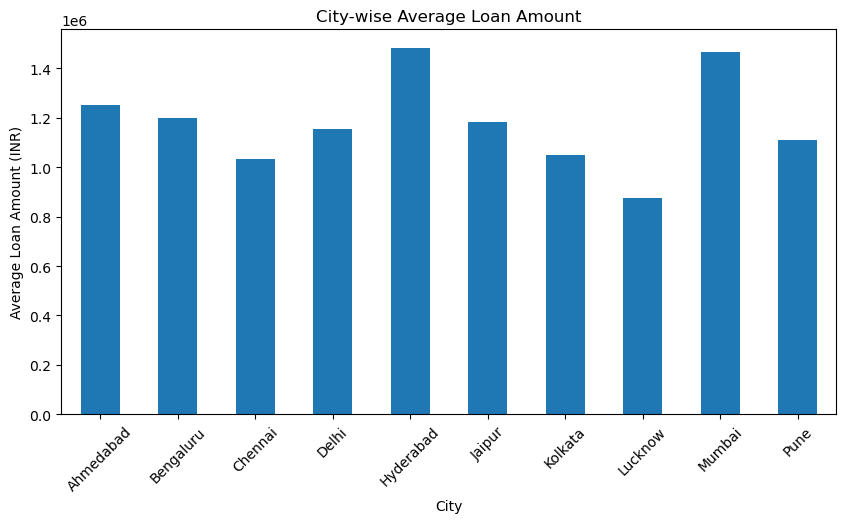

In [42]:
city_performance['Average_Loan_Amount'].plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('City-wise Average Loan Amount')
plt.xlabel('City')
plt.ylabel('Average Loan Amount (INR)')
plt.xticks(rotation=45)
plt.show()

### Phase-4

### Financial Analysis 💰📊
EV Financing Analyst Dataset mein Financial Analysis karne ke liye hum 4 important areas cover karenge:
1. EMI Affordability – Customer apni monthly income se EMI pay kar sakta hai ya nahi.
2. Disposable Income – Monthly expenses ke baad customer ke paas kitna paisa bachta hai.
3. Down-Payment Ratio – Customer vehicle purchase mein kitna percentage khud pay kar raha hai.
4. Loan Exposure – Company ne total kitne amount ka loan finance kiya hai ya karne ka proposal diya hai.

## EMI Affordability Analysis 💳 
Kya customer apni monthly disposable income se loan ki EMI afford kar sakta hai

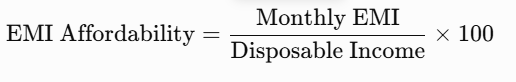


In [44]:
ev_financial['EMI_Affordability_Pct'] = (
    ev_financial['Monthly_EMI_INR'] /
    ev_financial['Monthly_Disposable_Income_INR']
) * 100

ev_financial[[
    'Application_ID',
    'Monthly_Disposable_Income_INR',
    'Monthly_EMI_INR',
    'EMI_Affordability_Pct'
]]

,Application_ID,Monthly_Disposable_Income_INR,Monthly_EMI_INR,EMI_Affordability_Pct
0,EVF001,23000,26330,114.48
1,EVF002,26000,31350,120.58
2,EVF003,13000,22050,169.62
3,EVF004,20000,25450,127.25
4,EVF005,45000,38650,85.89
5,EVF006,17000,23820,140.12
6,EVF007,13000,23900,183.85
7,EVF008,22000,26100,118.64
8,EVF009,21000,28300,134.76
9,EVF010,35000,35600,101.71


### Affordability status check 

In [45]:

ev_financial['EMI_Status'] = np.where(
    ev_financial['Monthly_EMI_INR'] <=
    ev_financial['Monthly_Disposable_Income_INR'],
    'Affordable',
    'Not Affordable'
)

ev_financial['EMI_Status'].value_counts()

EMI_Status
Not Affordable    27
Affordable         3
Name: count, dtype: int64

### Disposable Income Analysis 💵
Customer ke paas monthly expenses pay karne ke baad kitna paisa bachta hai?
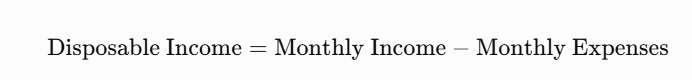

In [46]:
ev_financial['Disposable_Income'] = (
    ev_financial['Monthly_Income_INR'] -
    ev_financial['Monthly_Expenses_INR']
)

print("Average Disposable Income:",
      ev_financial['Disposable_Income'].mean())

print("Minimum Disposable Income:",
      ev_financial['Disposable_Income'].min())

print("Maximum Disposable Income:",
      ev_financial['Disposable_Income'].max())

Average Disposable Income: 24233.333333333332
Minimum Disposable Income: 13000
Maximum Disposable Income: 48000


### Financial Analysis- Data Visulization

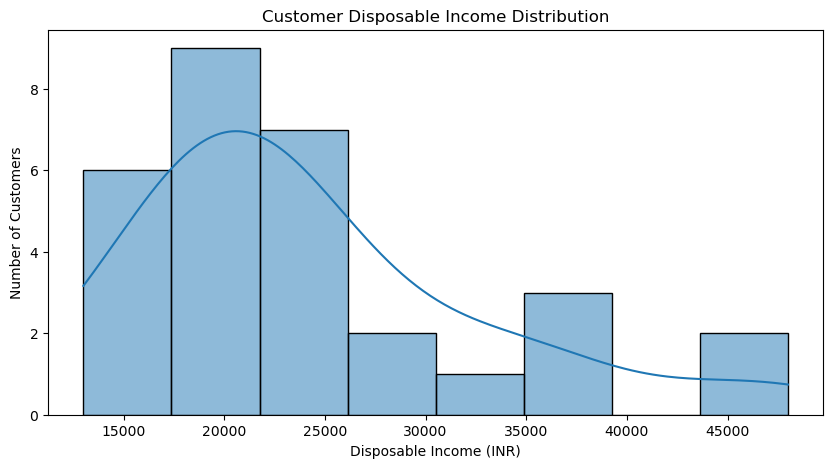

In [47]:
plt.figure(figsize=(10,5))

sns.histplot(
    ev_financial['Disposable_Income'],
    bins=8,
    kde=True
)

plt.title('Customer Disposable Income Distribution')
plt.xlabel('Disposable Income (INR)')
plt.ylabel('Number of Customers')

plt.show()

### Down-Payment Ratio Analysis 🚗
Customer vehicle purchase karne ke liye kitna percentage amount khud pay kar raha hai?

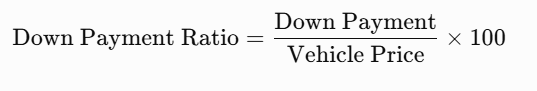

In [48]:
ev_financial['Down_Payment_Ratio'] = (
    ev_financial['Down_Payment_INR'] /
    ev_financial['Vehicle_Price_INR']
) * 100

print("Average Down Payment Ratio:",
      ev_financial['Down_Payment_Ratio'].mean())

Average Down Payment Ratio: 14.697848951023271


### Data Visulization-Down Payment Ratio

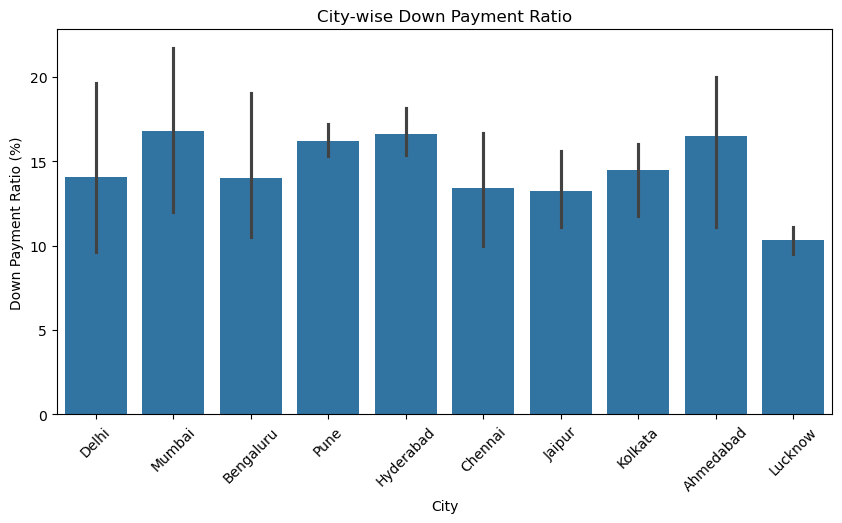

In [49]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=ev_financial,
    x='City',
    y='Down_Payment_Ratio'
)

plt.title('City-wise Down Payment Ratio')
plt.xlabel('City')
plt.ylabel('Down Payment Ratio (%)')
plt.xticks(rotation=45)

plt.show()

### Loan Exposure Analysis 🏦
Company total kitne amount ka loan finance kar rahi hai?
Loan Exposure calculate karne ke liye total loan amount ka sum nikalenge.

In [50]:
total_loan_exposure = (
    ev_financial['Loan_Amount_INR'].sum()
)

average_loan_exposure = (
    ev_financial['Loan_Amount_INR'].mean()
)

print("Total Loan Exposure:",
      total_loan_exposure)

print("Average Loan Exposure:",
      average_loan_exposure)

Total Loan Exposure: 35700000
Average Loan Exposure: 1190000.0


### Application Decision ke according Loan Exposure:

In [51]:
loan_exposure = ev_financial.groupby(
    'Application_Decision'
)['Loan_Amount_INR'].agg(
    ['count', 'sum', 'mean']
)

loan_exposure.columns = [
    'Applications',
    'Total_Loan_Exposure',
    'Average_Loan'
]

loan_exposure

,Applications,Total_Loan_Exposure,Average_Loan
Application_Decision,,,
Approved,21,27630000,"1,315,714.29"
Approved with Conditions,6,5570000,"928,333.33"
Rejected,3,2500000,"833,333.33"


### EMI vs Disposable Income Visualization 📊
Ye graph batayega ki customer ki EMI uski disposable income se kitni zyada ya kam hai.

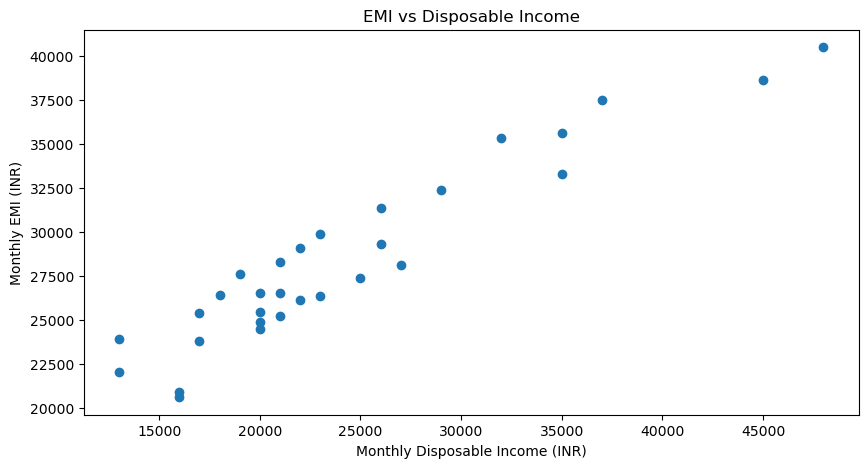

In [52]:
plt.figure(figsize=(10,5))

plt.scatter(
    ev_financial['Monthly_Disposable_Income_INR'],
    ev_financial['Monthly_EMI_INR']
)

plt.xlabel('Monthly Disposable Income (INR)')
plt.ylabel('Monthly EMI (INR)')
plt.title('EMI vs Disposable Income')

plt.show()

### Conclusion:
Final Business Insights 💡
Project report mein ye findings mention kar sakte hain:
1. EMI Affordability: 30 mein se 27 customers ki EMI disposable income se higher hai.
2. Disposable Income: Average disposable income ₹24,233 hai.
3. Down Payment: Customers average vehicle price ka 14.69% down payment kar rahe hain.
4. Loan Exposure: Total proposed loan exposure ₹3.57 crore hai.
5. Financial Risk: EMI affordability ek major concern hai. Loan approval se pehle customer ki repayment capacity carefully evaluate karni chahiye.

### Phase-4

### Credit Risk Analysis 💳📊
EV Financing Analyst Dataset mein Credit Risk Analysis ka main purpose hai identify karna ki kaunse customers mein loan rejection ka risk zyada hai.

Is analysis mein hum 3 important factors compare karenge:
1. Credit Score – Low credit score wale customers ka rejection rate kitna hai?
2. Employment Type – Private, Self-employed aur Gig Workers mein kis category ka rejection rate zyada hai?
3. Previous Loan Defaults – Jin customers ne pehle loan default kiya hai, unka rejection rate kitna hai?

### Credit Score-wise Rejection Rate Analysis 📉

In [53]:
ev_financial['Credit_Score_Category'] = pd.cut(
    ev_financial['Credit_Score'],
    bins=[0, 699, 749, 850],
    labels=['Low', 'Medium', 'High']
)

credit_analysis = ev_financial.groupby(
    'Credit_Score_Category',
    observed=False
).agg(
    Total_Applications=('Application_ID', 'count'),

    Rejected=('Application_Decision',
              lambda x: (x == 'Rejected').sum())
)

credit_analysis['Rejection_Rate'] = (
    credit_analysis['Rejected'] /
    credit_analysis['Total_Applications']
) * 100

credit_analysis

,Total_Applications,Rejected,Rejection_Rate
Credit_Score_Category,,,
Low,10,3,30.00
Medium,15,0,0.00
High,5,0,0.00


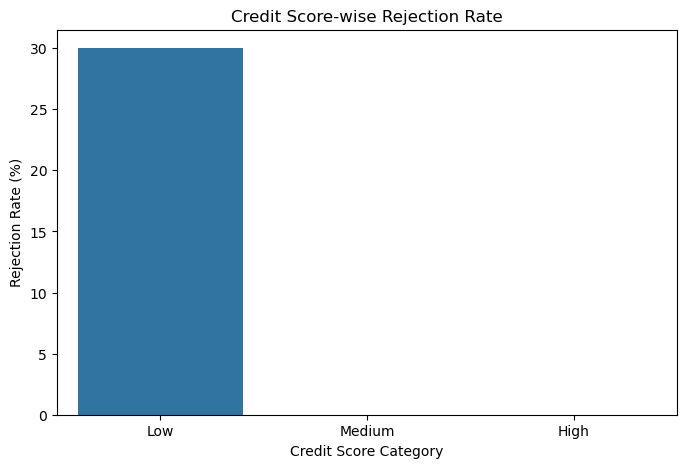

In [54]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=credit_analysis.reset_index(),
    x='Credit_Score_Category',
    y='Rejection_Rate'
)

plt.title('Credit Score-wise Rejection Rate')
plt.xlabel('Credit Score Category')
plt.ylabel('Rejection Rate (%)')

plt.show()

### Employment Type-wise Rejection Analysis 👨‍💼

### Business Questions:
- Private employees ka rejection rate kitna hai?
- Self-employed customers ka rejection rate kitna hai?
- Gig Workers mein loan rejection zyada hai ya kam?

In [55]:
employment_analysis = ev_financial.groupby(
    'Employment_Type'
).agg(
    Total_Applications=('Application_ID', 'count'),

    Rejected=('Application_Decision',
              lambda x: (x == 'Rejected').sum())
)

employment_analysis['Rejection_Rate'] = (
    employment_analysis['Rejected'] /
    employment_analysis['Total_Applications']
) * 100

employment_analysis

,Total_Applications,Rejected,Rejection_Rate
Employment_Type,,,
Gig Worker,8,3,37.50
Private,14,0,0.00
Self-employed,8,0,0.00


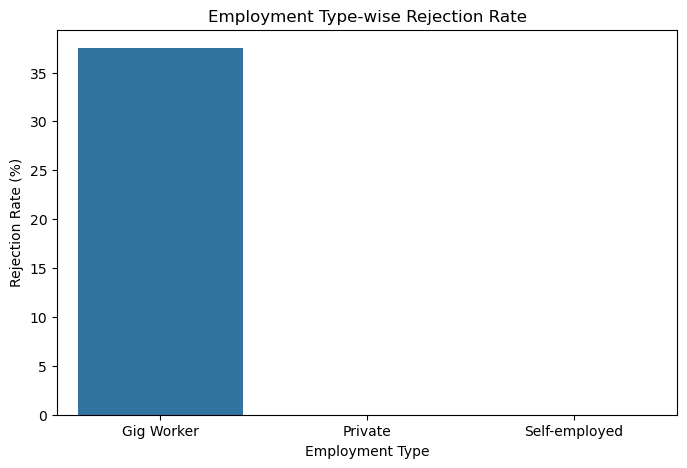

In [56]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=employment_analysis.reset_index(),
    x='Employment_Type',
    y='Rejection_Rate'
)

plt.title('Employment Type-wise Rejection Rate')
plt.xlabel('Employment Type')
plt.ylabel('Rejection Rate (%)')

plt.show()

Business Insight 💡: Gig Workers ka rejection rate sabse zyada 37.5% hai. Company ko Gig Workers ki income stability aur repayment capacity carefully evaluate karni chahiye.

### Previous Loan Defaults Analysis ⚠️

### Business Questions:
- Jin customers ne pehle loan default kiya hai, unka rejection rate kitna hai?
- Jin customers ka previous default nahi hai, unka rejection rate kitna hai?
- Previous loan default ka loan decision par kya impact hai?
Dataset mein Prior_Loan_Default_Flag column available hai:
- 1 = Previous Loan Default
- 0 = No Previous Loan Default

In [57]:
default_analysis = ev_financial.groupby(
    'Prior_Loan_Default_Flag'
).agg(
    Total_Applications=('Application_ID', 'count'),

    Rejected=('Application_Decision',
              lambda x: (x == 'Rejected').sum())
)

default_analysis['Rejection_Rate'] = (
    default_analysis['Rejected'] /
    default_analysis['Total_Applications']
) * 100

default_analysis.index = [
    'No Previous Default',
    'Previous Default'
]

default_analysis

,Total_Applications,Rejected,Rejection_Rate
No Previous Default,22,0,0.00
Previous Default,8,3,37.50


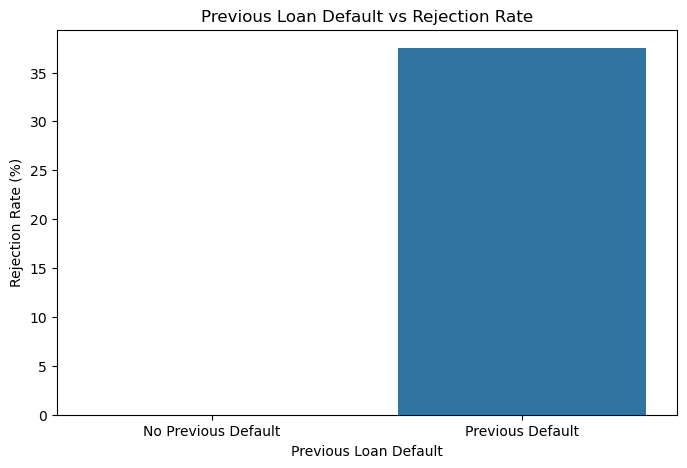

In [58]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=default_analysis.reset_index(),
    x='index',
    y='Rejection_Rate'
)

plt.title('Previous Loan Default vs Rejection Rate')
plt.xlabel('Previous Loan Default')
plt.ylabel('Rejection Rate (%)')

plt.show()

Business Insight 💡: Previous loan default wale customers mein rejection rate 37.5% hai, jabki no-default group mein 0% hai. Previous repayment history credit risk assessment ka important factor hai.

### Combined Credit Risk Analysis 📊
Ab thino factors ko ek saath compare karenge, taaki pata chale ki sabse zyada rejection kis category mein hai.

In [59]:
risk_factors = pd.DataFrame({

    'Credit Score': [
        credit_analysis.loc['Low', 'Rejection_Rate'],
        credit_analysis.loc['Medium', 'Rejection_Rate'],
        credit_analysis.loc['High', 'Rejection_Rate']
    ],

    'Employment Type': [
        employment_analysis.loc['Gig Worker', 'Rejection_Rate'],
        employment_analysis.loc['Private', 'Rejection_Rate'],
        employment_analysis.loc['Self-employed', 'Rejection_Rate']
    ],

    'Previous Default': [
        default_analysis.loc['Previous Default', 'Rejection_Rate'],
        default_analysis.loc['No Previous Default', 'Rejection_Rate'],
        np.nan
    ]

}, index=['High Risk Group', 'Other Group 1', 'Other Group 2'])

risk_factors

,Credit Score,Employment Type,Previous Default
High Risk Group,30.00,37.50,37.50
Other Group 1,0.00,0.00,0.00
Other Group 2,0.00,0.00,NaN


### Final Business Insights 💡
 project report mein ye findings likh sakte hain:
 
1. Credit Score Risk: Low credit score customers ka rejection rate 30% hai.
2. Employment Risk: Gig Workers mein rejection rate highest 37.5% hai.
3. Previous Default Risk: Previous loan default wale customers ka rejection rate 37.5% hai.
4. Private Employees: Private employees aur self-employed groups mein koi application reject nahi hui.
5. Risk Management: Loan approval se pehle credit score, employment stability aur previous repayment history check karna important hai.